# 加载数据

In [1]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer   # 列转换器
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer #填充器

# 1. 加载数据
df = pd.read_csv('../data/house_prices.csv')
df.drop(["Id"], axis=1, inplace=True)
print(df.shape)

(1460, 80)


# 2. 划分数据集

In [2]:
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']
x_train1, x_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.2, random_state=42)
# 3. 特征工程：数值型和类别型分别处理
## object 包括日期和文本
num_features = X.select_dtypes(exclude=['object']).columns
cat_features = X.select_dtypes(include=['object']).columns #str

/var/folders/fd/6b9qpfy15fz4z3mcnr6jvjc40000gn/T/ipykernel_89079/2815562737.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X.select_dtypes(include=['object']).columns #str


# 定义转换器V1

In [3]:
ct = ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(),cat_features),
    ])

# 定义转换器V2

In [4]:
num_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler()),
])
cat_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),# 返回的数据不能是压缩，要展开原始
    ])

ct = ColumnTransformer([
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features),
    ])


In [5]:
x_train2 = ct.fit_transform(x_train1)
x_test2 = ct.transform(x_test1)

# 4. 转换成Tensor
x_train = torch.tensor(x_train2).float()
x_val = torch.tensor(x_test2).float()
y_train = torch.tensor(y_train1.values).float()
y_val = torch.tensor(y_test1.values).float()

print(x_train.shape)

torch.Size([1168, 301])


# 数据加载到模型

In [6]:
import torch
from matplotlib import pyplot as plt
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

# 2. 定义训练超参数
batch_size = 64
lr = 0.1
epochs = 500

# 3. 构建数据集和加载器
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)



# 5. 定义模型

In [7]:
# 4. 定义设备
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 5. 定义模型
feature_num = x_train.shape[1]
model = nn.Sequential(
    nn.Linear(feature_num, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 1),
).to(device)


# 参数初始化函数

In [8]:

def init_params(layer):
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal_(layer.weight)
model.apply(init_params)



Sequential(
  (0): Linear(in_features=301, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=128, out_features=1, bias=True)
)

# 6. 定义损失函数和优化器

In [9]:
optimizer = optim.SGD(model.parameters(), lr=lr)

In [10]:
def loss_fn(y_pred, y_true):
    y_pred = torch.clamp(y_pred, 1, float('inf'))
    mse = nn.MSELoss()
    loss = torch.sqrt(mse(torch.log(y_pred), torch.log(y_true)))
    return loss

# 7. 模型训练和验证

In [11]:
train_loss_list = []
val_loss_list = []

for epoch in range(epochs):
    # 7.1 训练
    model.train()
    train_total_loss = 0
    for input, target in train_loader:
        input, target = input.to(device), target.to(device)
        # 7.1.1 前向传播，计算模型预测输出值
        output = model(input)
        # 7.1.2 计算损失
        loss = loss_fn(output.squeeze(), target)
        # 7.1.3 反向传播，计算梯度
        loss.backward()
        # 7.1.4 更新参数
        optimizer.step()
        # 7.1.5 梯度清零
        optimizer.zero_grad()
        # 累加损失
        train_total_loss += loss.item()
    # 计算平均训练损失
    train_loss = train_total_loss / len(train_loader)
    train_loss_list.append(train_loss)

    # 7.2 验证
    model.eval()
    val_total_loss = 0

    with torch.no_grad():
        for input, target in val_loader:
            input, target = input.to(device), target.to(device)
            # 7.2.1 前向传播，计算模型预测输出值
            output = model(input)
            # 7.2.2 计算损失
            loss = loss_fn(output.squeeze(), target)
            # 累加损失
            val_total_loss += loss.item()
        # 计算平均训练损失和准确率
        val_loss = val_total_loss / len(val_loader)
        val_loss_list.append(val_loss)

    # 本轮训练和验证结束，打印相关指标
    print(f"Epoch: {epoch+1}   train loss: {train_loss:.6f}, val loss: {val_loss:.6f}")



Epoch: 1   train loss: 10.808258, val loss: 10.023741
Epoch: 2   train loss: 9.695105, val loss: 9.472778
Epoch: 3   train loss: 9.351074, val loss: 9.191014
Epoch: 4   train loss: 9.133975, val loss: 9.009679
Epoch: 5   train loss: 8.970971, val loss: 8.860270
Epoch: 6   train loss: 8.836313, val loss: 8.734786
Epoch: 7   train loss: 8.724998, val loss: 8.630164
Epoch: 8   train loss: 8.614356, val loss: 8.531307
Epoch: 9   train loss: 8.532515, val loss: 8.446177
Epoch: 10   train loss: 8.433490, val loss: 8.371046
Epoch: 11   train loss: 8.370974, val loss: 8.295323
Epoch: 12   train loss: 8.297380, val loss: 8.231563
Epoch: 13   train loss: 8.229831, val loss: 8.172725
Epoch: 14   train loss: 8.169902, val loss: 8.115521
Epoch: 15   train loss: 8.102081, val loss: 8.050394
Epoch: 16   train loss: 8.054297, val loss: 8.000551
Epoch: 17   train loss: 8.002999, val loss: 7.954391
Epoch: 18   train loss: 7.955328, val loss: 7.903664
Epoch: 19   train loss: 7.910091, val loss: 7.856079


# 画图对比

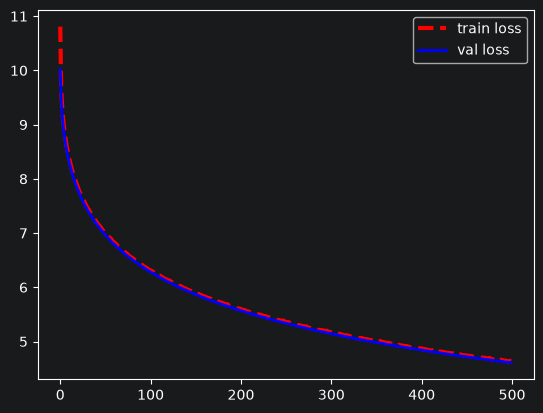

In [12]:
plt.plot(train_loss_list, "r--", label="train loss", linewidth=3)
plt.plot(val_loss_list, "b-", label="val loss", linewidth=2)
plt.legend()
plt.show()

# 总结
- 损失函数定义
- Dropout
- kaiming_normal_
- exclude=['object','str']
- SGD VS Adam
- Pipeline
- BatchNorm1d VS StandardScaler
- lr = 0.1 epochs = 500 超参调整问题